# Autonomous trajectories on a curved surface

Consider the scalar-output autonomous recurrence
\[
y_{k+2}=\frac{y_k+y_{k+1}^2}{2}.
\]
It has a two-dimensional state $x_k=(r_k,s_k)$, with
\[
x_{k+1}=\begin{bmatrix}s_k\\(r_k+s_k^2)/2\end{bmatrix},\qquad y_k=r_k.
\]
There is no input ($m=0$), and $p=1$. Initialize $x_0=(a,b)\in[-1,1]^2$; this box is forward invariant.

## Complete trajectory coordinates

Choose $L=3$ (for example, $T_{\mathrm{ini}}=2$, $T_f=1$). Every point is the complete trajectory
\[
w(a,b)=\operatorname{col}(y_0,y_1,y_2)
=\operatorname{col}\bigl(a,b,(a+b^2)/2\bigr)\in\mathbb R^3.
\]
These points form the exact surface $y_2=(y_0+y_1^2)/2$. The Jacobian with respect to $(a,b)$ is
\[
D w=\begin{bmatrix}1&0\\0&1\\1/2&b\end{bmatrix},
\]
which has rank two everywhere. Curvature appears in the $b$ direction. With $L=2$, the trajectory family is just the flat square $(a,b)$.

The surface consists of trajectories from **different initial conditions**. A single fixed initial condition generates one rollout; it need not cover this surface. A smooth first-order scalar autonomous system would generally yield only a one-parameter family.

In [1]:
from pathlib import Path
import sys
import numpy as np
from IPython.display import Image, display

folder = Path.cwd()
if not (folder / "autonomous_trajectory_surface.py").exists():
    folder = folder / "notebooks" / "motivation"
sys.path.insert(0, str(folder.resolve()))
from autonomous_trajectory_surface import simulate, hankel, validate, paper_figure


## Hankel columns and numerical checks

For a record $y_0,\ldots,y_{N-1}$,
\[
H_3(y)=\begin{bmatrix}
y_0&y_1&\cdots&y_{N-3}\\
y_1&y_2&\cdots&y_{N-2}\\
y_2&y_3&\cdots&y_{N-1}
\end{bmatrix}.
\]
Every column satisfies the same surface equation. The checks below use 100 independent 40-sample rollouts, building Hankel matrices separately before concatenation. No window crosses an experiment boundary. The plotted points are the first length-three windows from 529 grid initial conditions in the displayed subpatch $[-0.6,0.6]\times[-1,1]$.

In [2]:
windows, H, metrics = validate()
metrics

{'input_dimension': 0,
 'output_dimension': 1,
 'state_dimension': 2,
 'L': 3,
 'trajectory_ambient_dimension': 3,
 'intrinsic_dimension': 2,
 'plotted_complete_windows': 529,
 'validation_rollouts': 100,
 'plotted_y0_range': [-0.6, 0.6],
 'plotted_y1_range': [-1, 1],
 'samples_per_rollout': 40,
 'validated_Hankel_columns': 3800,
 'max_dynamics_residual': 5.551115123125783e-17,
 'max_absolute_output': 0.9885883754043117,
 'affine_rank_of_plotted_family': 3}

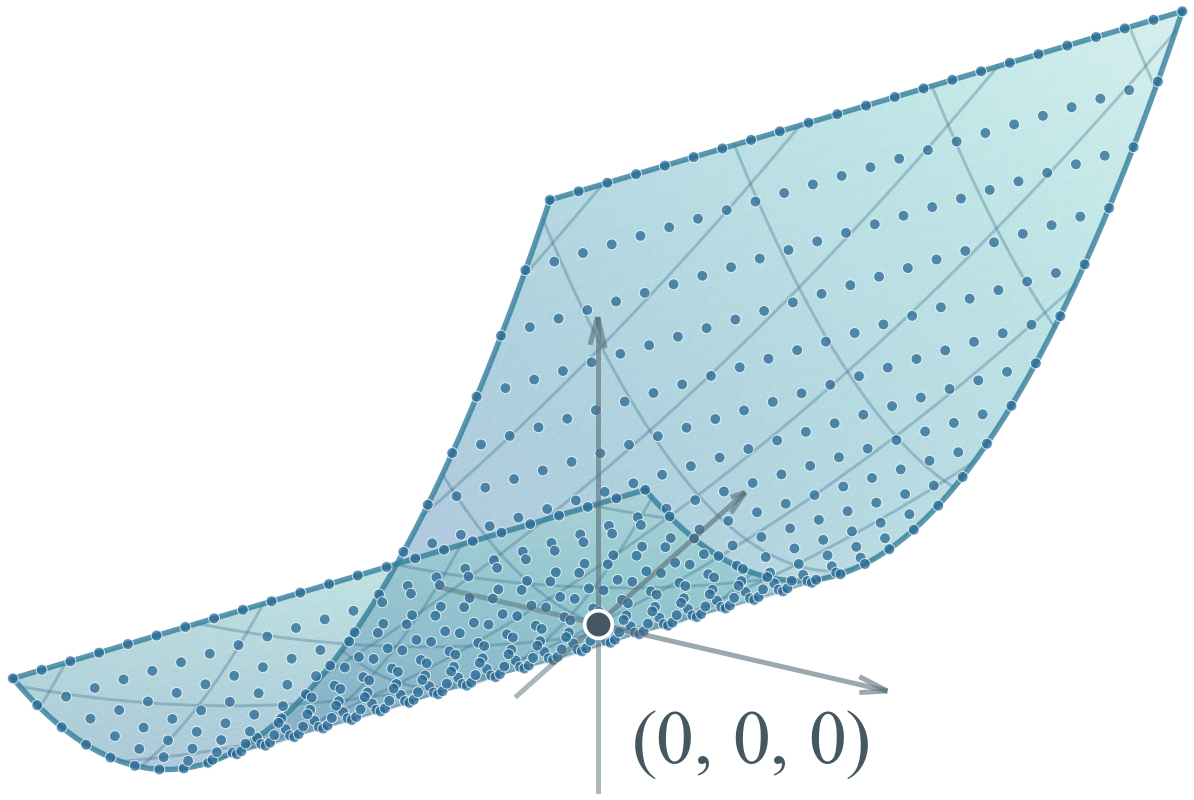

In [3]:
plotted = paper_figure()
assert np.array_equal(plotted, windows)
display(Image(filename=str(folder / "figures" / "autonomous_trajectory_paper.png"), width=600))

The plotted coordinates are the actual samples $(y_0,y_1,y_2)$: no dimensionality reduction is used. The origin $(0,0,0)$ is generated by the zero equilibrium and is marked on the surface. Three subtle, darker, unlabeled coordinate axes intersect at this actual origin. There are no measurement ticks. The former red trajectory point and its coordinate annotation are removed.

The camera and axis proportions retain the original orientation. The plotted patch is $a\in[-0.6,0.6]$, $b\in[-1,1]$; every blue point is a complete, valid trajectory. The curved mesh lines are sampled from the same exact trajectory family. The blue–teal gradient varies continuously with $y_2$, with subtle lighting and 50% surface opacity.

Exports: [PDF](figures/autonomous_trajectory_paper.pdf), [SVG](figures/autonomous_trajectory_paper.svg), [PNG](figures/autonomous_trajectory_paper.png). The figure uses Times New Roman, no title, and a tight crop on all four sides. The current exported size is 1.990 × 1.333 inches; scale it to the wrapfigure width in LaTeX.

A concise paper passage is provided in [autonomous_trajectory_example.tex](autonomous_trajectory_example.tex).